# Prática 2 — Classificação de dígitos de hidrômetros com AlexNet, VGG16 e ResNet18

**VC001 — Visão Computacional, CESAR School, 2026.2**
Ivan Edward · Davi Melo · Elizabete Barbosa

Pipeline completo: aquisição do dataset WaterMeters (Kaggle) → análise exploratória → construção do dataset de
dígitos (faixa 384×64, 8 recortes 48×64, correção de orientação) → treino de `smallcnn`, `alexnet`, `vgg16_bn` e
`resnet18` sob protocolo único → avaliação no conjunto de teste.

> **Licença CC BY-NC-ND 4.0.** As células marcadas com a tag `dataset-image` exibem imagens do dataset e têm a
> saída removida antes do commit (`python scripts/check_entrega.py --strip`).

In [1]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')  # determinismo do cuBLAS (antes de importar torch)

import ast, hashlib, random, re, shutil, time, zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, Dataset
from torchvision import models
from torchvision.transforms import v2

ROOT = Path.cwd()
DATA = ROOT / 'data' / 'WaterMeters'
DIGITS = ROOT / 'digits'
CKPT = ROOT / 'checkpoints'
FIG = ROOT / 'figures'
REP = ROOT / 'reports'
for p in (CKPT, FIG, REP):
    p.mkdir(exist_ok=True)

SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
QUICK = os.environ.get('WM_QUICK') == '1'  # modo de teste rápido (desligado na execução oficial)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)


set_seed()
print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| opencv', cv2.__version__)
print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else '')

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | opencv 5.0.0
device: cuda NVIDIA GeForce RTX 4070 SUPER


In [2]:
# Paleta categórica fixa por modelo (mesma cor em todas as figuras) e estilo comum dos gráficos
MODELS = ['smallcnn', 'alexnet', 'vgg16_bn', 'resnet18']
COLORS = {'smallcnn': '#2a78d6', 'alexnet': '#eb6834', 'vgg16_bn': '#1baf7a', 'resnet18': '#eda100'}
MARKERS = {'smallcnn': 'o', 'alexnet': 's', 'vgg16_bn': 'D', 'resnet18': '^'}
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight', 'figure.facecolor': 'white',
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'axes.titlesize': 11, 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.8, 'xtick.color': INK2, 'ytick.color': INK2, 'lines.linewidth': 2,
    'lines.markersize': 7, 'legend.frameon': False, 'font.size': 10,
})

## Parte 1 — Aquisição dos dados

Download do zip pela API do Kaggle: usa a API autenticada (`~/.kaggle/kaggle.json`) se houver credencial e, se não
houver, o endpoint público da mesma API (`/api/v1/datasets/download/...`), que funciona sem login para datasets públicos.
Se o zip já estiver em `data/`, o download é pulado. Em seguida, verificações de integridade do zip (CRC de todos os
membros e SHA-256) e da estrutura extraída.

In [3]:
KAGGLE_ID = 'tapakah68/yandextoloka-water-meters-dataset'
ZIP_PATH = ROOT / 'data' / 'watermeters.zip'
ZIP_SHA256 = '1d3fd2841bde91f50eb14c6f9a5ae509f6f8c42fb190893e1741520806586a66'  # versão baixada em 15/10/2026

if not ZIP_PATH.exists():
    ZIP_PATH.parent.mkdir(exist_ok=True)
    try:  # API autenticada (kaggle.json)
        from kaggle.api.kaggle_api_extended import KaggleApi
        api = KaggleApi()
        api.authenticate()
        api.dataset_download_files(KAGGLE_ID, path=ZIP_PATH.parent, quiet=False)
        (ZIP_PATH.parent / (KAGGLE_ID.split('/')[1] + '.zip')).rename(ZIP_PATH)
        print('download: API autenticada do Kaggle')
    except (Exception, SystemExit) as e:  # sem credencial a API chama sys.exit; usa o endpoint público
        import urllib.request
        print(f'API autenticada indisponível ({type(e).__name__}); usando o endpoint público da API do Kaggle')
        urllib.request.urlretrieve(f'https://www.kaggle.com/api/v1/datasets/download/{KAGGLE_ID}', ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH) as z:
    bad = z.testzip()  # confere o CRC de todos os membros
    members = z.namelist()
    if not (DATA / 'data.csv').exists():
        z.extractall(ROOT / 'data')
sha = hashlib.sha256(ZIP_PATH.read_bytes()).hexdigest()
print(f'zip: {ZIP_PATH.stat().st_size/1e6:.1f} MB | {len(members)} membros | CRC ok: {bad is None}')
print(f'sha256: {sha} | igual à versão usada neste trabalho: {sha == ZIP_SHA256}')
assert bad is None
print('dataset em', DATA.relative_to(ROOT))

zip: 1029.9 MB | 3733 membros | CRC ok: True
sha256: 1d3fd2841bde91f50eb14c6f9a5ae509f6f8c42fb190893e1741520806586a66 | igual à versão usada neste trabalho: True
dataset em data\WaterMeters


In [4]:
df = pd.read_csv(DATA / 'data.csv')
folders = {f: sorted(p.name for p in (DATA / f).iterdir()) for f in ('images', 'masks', 'collage')}
print('linhas em data.csv:', len(df))
for f, names in folders.items():
    print(f'{f:8s}: {len(names)} arquivos')

# 1) mesmos nomes em todas as pastas e no csv
assert set(folders['images']) == set(folders['masks']) == set(folders['collage']) == set(df.photo_name)
assert df.photo_name.is_unique

# 2) todo arquivo abre e imagem/máscara/colagem têm o mesmo tamanho
problems, sizes = [], {}
for name in df.photo_name:
    im = cv2.imread(str(DATA / 'images' / name))
    sizes[name] = im.shape[:2] if im is not None else (0, 0)
    mk = cv2.imread(str(DATA / 'masks' / name), cv2.IMREAD_GRAYSCALE)
    co = cv2.imread(str(DATA / 'collage' / name))
    if im is None or mk is None or co is None or not (im.shape[:2] == mk.shape == co.shape[:2]):
        problems.append(name)
print('arquivos ilegíveis ou com tamanhos divergentes:', len(problems))
assert not problems

# 3) colunas
print(df.dtypes)
df.head(3)

linhas em data.csv: 1244
images  : 1244 arquivos
masks   : 1244 arquivos
collage : 1244 arquivos


arquivos ilegíveis ou com tamanhos divergentes: 0
photo_name        str
value         float64
location          str
dtype: object


,photo_name,value,location
0,id_53_value_595_825.jpg,595.825,"{'type': 'polygon', 'data': [{'x': 0.30788, 'y..."
1,id_553_value_65_475.jpg,65.475,"{'type': 'polygon', 'data': [{'x': 0.26133, 'y..."
2,id_407_value_21_86.jpg,21.860,"{'type': 'polygon', 'data': [{'x': 0.27545, 'y..."


## Parte 2 — Análise exploratória

Conteúdo de cada pasta, geometria das anotações, distribuição das leituras e consistência entre as fontes de rótulo
(nome do arquivo × coluna `value`).

In [5]:
# Exemplo de imagem, máscara e colagem (saída removida antes do commit)
ex = df.photo_name.iloc[0]
fig, axs = plt.subplots(1, 3, figsize=(11, 4.5))
for ax, f in zip(axs, ('images', 'masks', 'collage')):
    im = cv2.imread(str(DATA / f / ex))
    ax.imshow(im[..., ::-1]); ax.set_title(f); ax.axis('off')
plt.show()

In [6]:
def polygon(loc):
    d = ast.literal_eval(loc)
    return d['type'], np.array([[p['x'], p['y']] for p in d['data']], np.float32)

df['img_h'] = df.photo_name.map(lambda n: sizes[n][0])  # tamanhos lidos na verificação de integridade
df['img_w'] = df.photo_name.map(lambda n: sizes[n][1])
df['poly_type'] = df.location.map(lambda s: polygon(s)[0])
df['n_vertices'] = df.location.map(lambda s: len(polygon(s)[1]))

mk = cv2.imread(str(DATA / 'masks' / ex), cv2.IMREAD_GRAYSCALE)
print('valores distintos na máscara (JPEG):', np.unique(mk).size, '| fração > 127:', (mk > 127).mean().round(4))
print('resoluções mais comuns (h×w):', pd.Series([f'{h}×{w}' for h, w in zip(df.img_h, df.img_w)]).value_counts().head(4).to_dict())
print('orientação da foto (retrato/paisagem):', (df.img_h > df.img_w).map({True: 'retrato', False: 'paisagem'}).value_counts().to_dict())
print('tipo de anotação:', df.poly_type.value_counts().to_dict())
print('vértices por polígono:', df.n_vertices.value_counts().sort_index().to_dict())

valores distintos na máscara (JPEG): 4 | fração > 127: 0.0073
resoluções mais comuns (h×w): {'1333×1000': 913, '1000×1333': 149, '1778×1000': 64, '1000×1778': 21}
orientação da foto (retrato/paisagem): {'retrato': 1044, 'paisagem': 200}
tipo de anotação: {'polygon': 1244}
vértices por polígono: {4: 505, 6: 508, 8: 231}


In [7]:
# Duas fontes de rótulo: o nome do arquivo (string) e a coluna value (float)
lab = df.photo_name.str.extract(r'^id_(?P<id>\d+)_value_(?P<int>\d+)_(?P<dec>\d+)\.jpg$')
assert lab.notna().all().all()
df = df.join(lab)
raw_value = pd.read_csv(DATA / 'data.csv', dtype=str).value  # value como texto, exatamente como está no csv
name_str = df['int'] + '.' + df['dec']

same_float = np.isclose(name_str.astype(float), df.value, atol=1e-9)
same_text = name_str == raw_value
print(f'nome == value (numérico):       {same_float.sum()} / {len(df)}')
print(f'nome == value (texto do csv):   {same_text.sum()} / {len(df)}')
print('exemplos de value com artefato de ponto flutuante:')
print(pd.DataFrame({'photo_name': df.photo_name, 'value (csv)': raw_value})[~same_text].head(5).to_string(index=False))

print('\ndígitos inteiros:', df['int'].str.len().value_counts().sort_index().to_dict())
print('casas decimais :', df['dec'].str.len().value_counts().sort_index().to_dict())
print('decimal == "0" :', (df['dec'] == '0').sum())

nome == value (numérico):       1244 / 1244
nome == value (texto do csv):   944 / 1244
exemplos de value com artefato de ponto flutuante:
              photo_name        value (csv)
id_851_value_305_162.jpg 305.16200000000003
id_1204_value_78_677.jpg  78.67699999999999
  id_71_value_90_216.jpg  90.21600000000001
id_924_value_625_593.jpg  625.5930000000001
id_112_value_365_387.jpg 365.38699999999994

dígitos inteiros: {1: 47, 2: 329, 3: 817, 4: 48, 5: 3}
casas decimais : {1: 41, 2: 87, 3: 1115, 4: 1}
decimal == "0" : 36


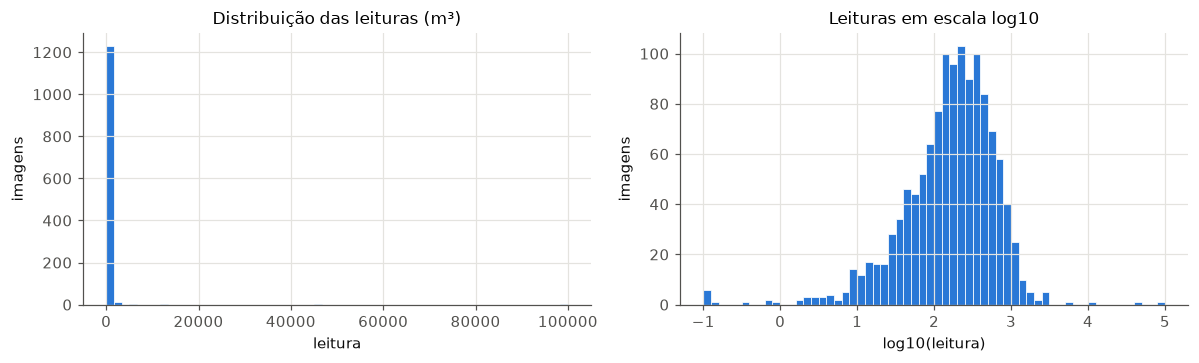

{'count': 1244.0, 'mean': 422.507, 'std': 3144.331, 'min': 0.0, '25%': 79.187, '50%': 188.808, '75%': 386.042, 'max': 99999.539}
leituras < 100 m³: 0.302 | < 1000 m³: 0.959


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].hist(df.value, bins=60, color=COLORS['smallcnn'], edgecolor='white', linewidth=0.5)
axs[0].set(title='Distribuição das leituras (m³)', xlabel='leitura', ylabel='imagens')
axs[1].hist(np.log10(df.value.clip(lower=0.1)), bins=60, color=COLORS['smallcnn'], edgecolor='white', linewidth=0.5)
axs[1].set(title='Leituras em escala log10', xlabel='log10(leitura)', ylabel='imagens')
plt.tight_layout(); plt.show()
print(df.value.describe().round(3).to_dict())
print('leituras < 100 m³:', (df.value < 100).mean().round(3), '| < 1000 m³:', (df.value < 1000).mean().round(3))

## Parte 3 — Construção do dataset de dígitos

**Rótulo.** O rótulo vem do **nome do arquivo** (string sem artefatos de float), validado contra `value`. Parte
inteira com zeros à esquerda até 5 dígitos; parte decimal completada com zeros à direita até 3 (o zero final foi
perdido na conversão para float: `70.940 → 70.94`). Imagens com mais de 5 inteiros ou mais de 3 decimais são
descartadas.

**Retificação.** Retângulo de área mínima (`cv2.minAreaRect`) do polígono anotado → homografia para 384×64. Usamos
o retângulo mínimo porque 739 polígonos têm 6 ou 8 vértices (contornam o "degrau" da moldura dos decimais).
Convenção base: o eixo longo vira a horizontal da faixa; visor horizontal é lido da esquerda para a direita e
visor vertical (eixo longo mais próximo da vertical da foto) é girado 90° para ser lido de cima para baixo.

**Orientação (de cabeça para baixo).** Decidimos se a faixa precisa de rotação de 180° com duas pistas sem usar o
rótulo:
1. **degrau do polígono** — nos polígonos de 6/8 vértices, a metade mais alta é a dos decimais (moldura maior), que
   deve ficar à direita;
2. **vermelho** — fração de pixels vermelhos nos 3/8 da direita × 3/8 da esquerda (decimais costumam ser vermelhos).

Ordem de decisão: degrau (se |Δaltura| > 5% da altura) → vermelho (só para visores verticais, se |Δ| > 0,05) → mantém
a base. O vermelho não é usado em visores horizontais porque, neles, a prior de estarem em pé é muito alta e o
vermelho gera falsos positivos (fundos rosados/alaranjados).

In [9]:
W, H, NPOS = 384, 64, 8
CW = W // NPOS  # 48


def parse_label(photo_name):
    # '00176881' para id_1000_value_176_881.jpg; None se não couber em 5 inteiros + 3 decimais
    m = re.fullmatch(r'id_\d+_value_(\d+)_(\d+)\.jpg', photo_name)
    ip, dp = m.groups()
    if len(ip) > 5 or len(dp) > 3:
        return None
    return ip.zfill(5) + dp.ljust(3, '0')


def strip_geometry(P):
    # centro, eixo longo u, eixo curto v, comprimentos e se o visor é vertical
    rect = cv2.minAreaRect(P)
    box = cv2.boxPoints(rect)
    e1, e2 = box[1] - box[0], box[2] - box[1]
    u = e1 if np.linalg.norm(e1) >= np.linalg.norm(e2) else e2
    u = u / np.linalg.norm(u)
    vertical = abs(u[1]) > abs(u[0])
    if (not vertical and u[0] < 0) or (vertical and u[1] < 0):
        u = -u  # base: horizontal esq->dir, vertical cima->baixo
    v = np.array([-u[1], u[0]], np.float32)  # rotação de +90° (sem espelhamento)
    L, S = max(rect[1]), min(rect[1])
    return np.array(rect[0], np.float32), u, v, L, S, vertical


def notch_cue(P, c, u, v, S):
    # (altura da metade direita - altura da metade esquerda) / S ; NaN se o polígono tem 4 vértices
    if len(P) <= 4:
        return np.nan
    q = P - c
    pu, pv = q @ u, q @ v
    hr = np.ptp(pv[pu > 0]) if (pu > 0).sum() >= 2 else 0.0
    hl = np.ptp(pv[pu < 0]) if (pu < 0).sum() >= 2 else 0.0
    return float((hr - hl) / S)


def red_cue(strip):
    hsv = cv2.cvtColor(strip, cv2.COLOR_BGR2HSV)
    red = ((hsv[..., 0] < 10) | (hsv[..., 0] > 165)) & (hsv[..., 1] > 80) & (hsv[..., 2] > 60)
    return float(red[:, W * 5 // 8:].mean() - red[:, :W * 3 // 8].mean())


def make_strip(img, loc):
    # retorna faixa BGR 384x64 já orientada + metadados da decisão
    h, w = img.shape[:2]
    P = polygon(loc)[1] * np.float32([w, h])
    c, u, v, L, S, vertical = strip_geometry(P)
    src = np.float32([c - L/2*u - S/2*v, c + L/2*u - S/2*v, c + L/2*u + S/2*v, c - L/2*u + S/2*v])
    dst = np.float32([[0, 0], [W, 0], [W, H], [0, H]])
    strip = cv2.warpPerspective(img, cv2.getPerspectiveTransform(src, dst), (W, H), flags=cv2.INTER_LINEAR)
    notch, red = notch_cue(P, c, u, v, S), red_cue(strip)
    if not np.isnan(notch) and abs(notch) > 0.05:
        cue, flip = 'degrau', notch < 0
    elif vertical and abs(red) > 0.05:
        cue, flip = 'vermelho', red < 0
    else:
        cue, flip = 'nenhuma', False
    if flip:
        strip = cv2.rotate(strip, cv2.ROTATE_180)
    return strip, dict(vertical=vertical, notch=notch, red=red, cue=cue, flip=flip, aspect=L / S)

In [10]:
splits = pd.read_csv(ROOT / 'splits.csv')
print('splits.csv:', splits.split.value_counts().to_dict(), '| sha256', hashlib.sha256((ROOT / 'splits.csv').read_bytes()).hexdigest()[:16])

df['label'] = df.photo_name.map(parse_label)
discarded = df[df.label.isna()]
valid = df[df.label.notna()].merge(splits, on='photo_name', how='inner')
print('válidas:', len(valid), '| descartadas:', len(discarded), discarded.photo_name.tolist())
assert set(valid.photo_name) == set(splits.photo_name)

if DIGITS.exists():
    shutil.rmtree(DIGITS)  # reconstrução do zero, sempre igual
(DIGITS / 'strips').mkdir(parents=True)

rows, meta = [], []
for r in valid.itertuples():
    img = cv2.imread(str(DATA / 'images' / r.photo_name))
    strip, info = make_strip(img, r.location)
    image_id = f'id_{r.id}'
    cv2.imwrite(str(DIGITS / 'strips' / f'{image_id}.png'), strip)
    meta.append(dict(image_id=image_id, photo_name=r.photo_name, split=r.split, label=r.label, **info))
    for pos in range(NPOS):
        digit = r.label[pos]
        out = DIGITS / r.split / digit / f'{image_id}_{pos}.png'
        out.parent.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(out), strip[:, pos * CW:(pos + 1) * CW])
        rows.append(dict(image_id=image_id, photo_name=r.photo_name, position=pos, digit=int(digit),
                         split=r.split, crop_path=out.relative_to(ROOT).as_posix()))

index = pd.DataFrame(rows)
index.to_csv(DIGITS / 'index.csv', index=False)
strips_meta = pd.DataFrame(meta)
strips_meta.to_csv(REP / 'strips_meta.csv', index=False)  # só metadados (sem imagens)
index.head()

splits.csv: {'train': 870, 'test': 187, 'val': 186} | sha256 ca4c5d8ad131d63e
válidas: 1243 | descartadas: 1 ['id_664_value_45_2676.jpg']


,image_id,photo_name,position,digit,split,crop_path
0,id_53,id_53_value_595_825.jpg,0,0,train,digits/train/0/id_53_0.png
1,id_53,id_53_value_595_825.jpg,1,0,train,digits/train/0/id_53_1.png
2,id_53,id_53_value_595_825.jpg,2,5,train,digits/train/5/id_53_2.png
3,id_53,id_53_value_595_825.jpg,3,9,train,digits/train/9/id_53_3.png
4,id_53,id_53_value_595_825.jpg,4,5,train,digits/train/5/id_53_4.png


In [11]:
# Verificações obrigatórias
n_crops = len(index)
per_img_split = index.groupby('image_id').split.nunique()
print(f'imagens válidas: {index.image_id.nunique()} | descartadas: {len(discarded)} | recortes: {n_crops}')
print('recortes por split:', index.split.value_counts().to_dict())
print('imagens em mais de um split:', (per_img_split > 1).sum())
assert index.image_id.nunique() == 1243 and len(discarded) == 1 and n_crops == 9944
assert (per_img_split == 1).all()
assert set(index[index.split == 'train'].image_id).isdisjoint(index[index.split == 'test'].image_id)
assert set(index[index.split == 'val'].image_id).isdisjoint(index[index.split == 'test'].image_id)
assert all((ROOT / p).exists() for p in index.crop_path)
assert all(cv2.imread(str(ROOT / p)).shape == (64, 48, 3) for p in index.crop_path.sample(200, random_state=0))
print('OK — todas as verificações passaram')

imagens válidas: 1243 | descartadas: 1 | recortes: 9944
recortes por split: {'train': 6960, 'test': 1496, 'val': 1488}
imagens em mais de um split: 0


OK — todas as verificações passaram


In [12]:
# Correção de orientação: quantas faixas foram corrigidas e por qual pista
sm = strips_meta
corrected = sm.vertical | sm.flip
print(f'faixas verticais (giradas 90°): {sm.vertical.sum()}')
print(f'faixas giradas 180° (de cabeça para baixo): {sm.flip.sum()}  '
      f'[horizontais: {(sm.flip & ~sm.vertical).sum()}, verticais: {(sm.flip & sm.vertical).sum()}]')
print(f'total de faixas corrigidas (90° e/ou 180°): {corrected.sum()} de {len(sm)}')
print(pd.crosstab([sm.vertical.map({True: 'vertical', False: 'horizontal'}), sm.cue], sm.flip.map({True: 'girou 180°', False: 'manteve'}), margins=True))
dec = sm.dropna(subset=['notch'])
dec = dec[(dec.notch.abs() > 0.05) & (dec.red.abs() > 0.05)]
print(f'\nconcordância degrau × vermelho quando ambos são decisivos: {((dec.notch > 0) == (dec.red > 0)).mean():.3f} (n={len(dec)})')

faixas verticais (giradas 90°): 105
faixas giradas 180° (de cabeça para baixo): 45  [horizontais: 8, verticais: 37]
total de faixas corrigidas (90° e/ou 180°): 113 de 1243
flip                 girou 180°  manteve   All
vertical   cue                                
horizontal degrau             8      663   671
           nenhuma            0      467   467
vertical   degrau            26       32    58
           nenhuma            0       17    17
           vermelho          11       19    30
All                          45     1198  1243

concordância degrau × vermelho quando ambos são decisivos: 0.997 (n=607)


In [13]:
# Galeria de faixas corrigidas (saída removida antes do commit)
def show_strips(sub, title, n=12):
    sub = sub.head(n)
    fig, axs = plt.subplots(len(sub), 1, figsize=(6, 0.75 * len(sub)))
    for ax, r in zip(np.atleast_1d(axs), sub.itertuples()):
        ax.imshow(cv2.imread(str(DIGITS / 'strips' / f'{r.image_id}.png'))[..., ::-1])
        ax.set_title(f'{r.label}  ({r.cue}, 180°={r.flip})', fontsize=8, loc='left'); ax.axis('off')
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_strips(sm[sm.vertical].sample(12, random_state=0), 'Visores verticais após correção')
show_strips(sm[sm.flip & ~sm.vertical], 'Visores horizontais girados 180°')

In [14]:
# Auditoria dos rótulos com decimal "0": em quase todos o polígono cobre só os 5 dígitos inteiros.
# Inspeção visual das 36 faixas: só 3 mostram o visor completo (8 rodas). As demais geram 8 recortes desalinhados.
FULL_DISPLAY_DEC0 = {'id_799_value_22_0.jpg', 'id_563_value_3_0.jpg', 'id_478_value_226_0.jpg'}
sm['dec0'] = sm.photo_name.str.endswith('_0.jpg')
sm['integer_only'] = sm.dec0 & ~sm.photo_name.isin(FULL_DISPLAY_DEC0)
print('rótulos com decimal "0":', sm.dec0.sum(), '| polígono só com a parte inteira (auditoria visual):', sm.integer_only.sum())
print(sm[sm.integer_only].split.value_counts().to_dict())
print('proporção (L/S) do polígono — só inteiros vs demais:')
print(sm.groupby('integer_only').aspect.describe().round(2))

rótulos com decimal "0": 36 | polígono só com a parte inteira (auditoria visual): 33
{'train': 21, 'val': 8, 'test': 4}
proporção (L/S) do polígono — só inteiros vs demais:
               count  mean   std   min   25%   50%   75%   max
integer_only                                                  
False         1210.0  5.11  0.90  2.83  4.38  5.01  5.65  8.73
True            33.0  4.34  0.44  3.81  4.04  4.22  4.65  5.54


In [15]:
show_strips(sm[sm.integer_only], 'Polígono só com a parte inteira (rótulo xxx.000 imposto a 5 dígitos)', n=8)

recortes por dígito (todos os splits): {0: 3549, 1: 1003, 2: 777, 3: 779, 4: 698, 5: 677, 6: 638, 7: 620, 8: 613, 9: 590}

recortes por dígito no treino: {0: 2482, 1: 718, 2: 525, 3: 553, 4: 488, 5: 480, 6: 450, 7: 450, 8: 400, 9: 414}


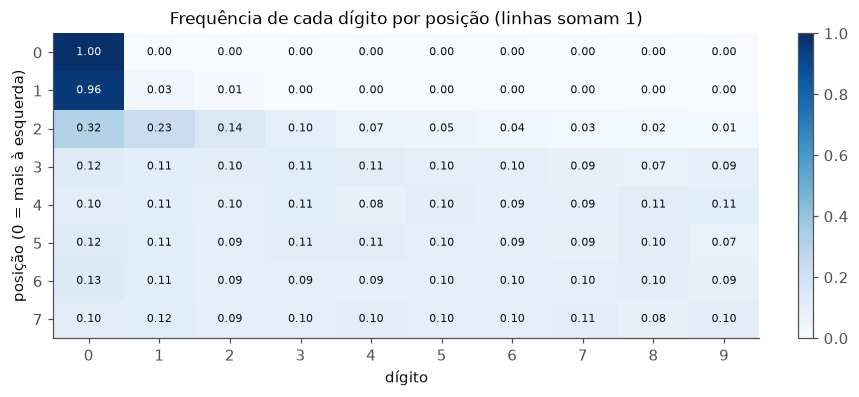

In [16]:
# Distribuição dos dígitos (classe) — total e por posição
ct = pd.crosstab(index.position, index.digit)
print('recortes por dígito (todos os splits):', index.digit.value_counts().sort_index().to_dict())
print('\nrecortes por dígito no treino:', index[index.split == 'train'].digit.value_counts().sort_index().to_dict())

fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(ct.values / ct.values.sum(1, keepdims=True), cmap='Blues', vmin=0, vmax=1, aspect='auto')
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = ct.values[i, j] / ct.values[i].sum()
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7, color='white' if v > 0.55 else INK)
ax.set(xticks=range(10), yticks=range(8), xlabel='dígito', ylabel='posição (0 = mais à esquerda)',
       title='Frequência de cada dígito por posição (linhas somam 1)')
ax.grid(False); fig.colorbar(im, ax=ax, fraction=0.03)
plt.savefig(FIG / 'eda_digits_by_position.png'); plt.show()

## Parte 4 — Treinamento dos quatro modelos

Protocolo idêntico ao roteiro: AdamW + OneCycleLR, `CrossEntropyLoss(label_smoothing=0.1)`, 1ª época com backbone
congelado (pré-treinados), early stopping pelo F1-macro da validação (paciência 3), `seed=42`, augmentation
`RandomAffine(5°, translate 5%, scale 0,95–1,05)` + `ColorJitter(brilho 0,3, contraste 0,3)`, sem flip.
Todas as entradas são normalizadas com média/desvio do ImageNet (inclusive a `smallcnn`, para manter o protocolo
único). A "cabeça" é a última camada linear (nova, 10 saídas); o "backbone" é todo o resto da rede.

Detalhes de implementação (iguais para os quatro modelos):
- os 9944 recortes são carregados em memória (uint8); o augmentation é aplicado no recorte 64×48 e o redimensionamento
  para 128×128 (bilinear) + normalização acontecem na GPU;
- `weight_decay=0.01` (padrão do AdamW), OneCycleLR com `max_lr` = LR de cada grupo e `total_steps = épocas × batches`;
- a coluna `seconds` do histórico mede **só o treino** da época (sem validação), com `cuda.synchronize`;
- o `AdaptiveAvgPool2d` das redes pré-treinadas é substituído por uma implementação matematicamente idêntica
  (verificada com `assert`) cujo backward é determinístico na GPU — sem isso, AlexNet e VGG variavam até 0,3 p.p.
  entre execuções com a mesma seed.

In [17]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
CUDA = DEVICE.type == 'cuda'

CFG = {  # batch: coluna CUDA / coluna MPS-CPU do roteiro
    'smallcnn': dict(weights=None, size=(64, 48), batch=256 if CUDA else 128, lr_head=1e-3, lr_backbone=None, epochs=10),
    'alexnet': dict(weights='IMAGENET1K_V1', size=(128, 128), batch=128 if CUDA else 64, lr_head=1e-3, lr_backbone=1e-4, epochs=8),
    'vgg16_bn': dict(weights='IMAGENET1K_V1', size=(128, 128), batch=32 if CUDA else 16, lr_head=1e-3, lr_backbone=1e-5, epochs=8),
    'resnet18': dict(weights='IMAGENET1K_V1', size=(128, 128), batch=128 if CUDA else 64, lr_head=1e-3, lr_backbone=1e-4, epochs=8),
}
PATIENCE = 3
if QUICK:
    print('ATENÇÃO: modo de teste rápido (2 épocas) — results.csv e history_*.csv NÃO são os oficiais')
    for c in CFG.values():
        c['epochs'] = 2
pd.DataFrame(CFG).T

,weights,size,batch,lr_head,lr_backbone,epochs
smallcnn,None,"(64, 48)",256,0.001,None,10
alexnet,IMAGENET1K_V1,"(128, 128)",128,0.001,0.0001,8
vgg16_bn,IMAGENET1K_V1,"(128, 128)",32,0.001,0.00001,8
resnet18,IMAGENET1K_V1,"(128, 128)",128,0.001,0.0001,8


In [18]:
def load_split(split):
    sub = index[index.split == split].reset_index(drop=True)
    X = np.stack([cv2.imread(str(ROOT / p))[..., ::-1] for p in sub.crop_path])  # RGB, (N, 64, 48, 3)
    X = torch.from_numpy(X.copy()).permute(0, 3, 1, 2).contiguous()              # uint8, (N, 3, 64, 48)
    y = torch.tensor(sub.digit.values, dtype=torch.long)
    return X, y, sub


DATASETS = {s: load_split(s) for s in ('train', 'val', 'test')}
for s, (X, y, _) in DATASETS.items():
    print(f'{s:5s} X={tuple(X.shape)} y={tuple(y.shape)}')

AUG = v2.Compose([
    v2.RandomAffine(degrees=5, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    v2.ColorJitter(brightness=0.3, contrast=0.3),
])


class CropDataset(Dataset):
    def __init__(self, X, y, train):
        self.X, self.y, self.train = X, y, train

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.X[i]
        return (AUG(x) if self.train else x), self.y[i]


def prep(x, size):
    # uint8 (B,3,64,48) na GPU -> float normalizado no tamanho de entrada do modelo
    x = x.to(DEVICE, non_blocking=True).float() / 255.0
    if tuple(x.shape[-2:]) != tuple(size):
        x = F.interpolate(x, size=size, mode='bilinear', align_corners=False)
    return (x - MEAN.to(DEVICE)) / STD.to(DEVICE)

train X=(6960, 3, 64, 48) y=(6960,)
val   X=(1488, 3, 64, 48) y=(1488,)
test  X=(1496, 3, 64, 48) y=(1496,)


In [19]:
class SmallCNN(nn.Module):
    # CNN pequena treinada do zero: 3 blocos conv-conv-pool (32/64/128 canais) + GAP + linear
    def __init__(self, n_classes=10):
        super().__init__()

        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))

        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.pool = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3))
        self.head = nn.Linear(128, n_classes)

    def forward(self, x):
        return self.head(self.pool(self.features(x)))


class DeterministicAdaptiveAvgPool2d(nn.Module):
    # Mesmo resultado de nn.AdaptiveAvgPool2d, calculado como P_h · x · P_wᵀ com matrizes de média fixas.
    # Motivo: com entrada 128×128 a AlexNet (3×3→6×6) e a VGG (4×4→7×7) usam o pooling adaptativo para AMPLIAR o mapa,
    # e o backward desse caso na GPU usa somas atômicas (não determinístico). Multiplicação de matrizes é determinística.
    def __init__(self, output_size):
        super().__init__()
        self.output_size = (output_size, output_size) if isinstance(output_size, int) else tuple(output_size)
        self._cache = {}

    @staticmethod
    def _matrix(n_in, n_out):
        M = torch.zeros(n_out, n_in)
        for i in range(n_out):
            start, end = (i * n_in) // n_out, -(-((i + 1) * n_in) // n_out)  # mesmos limites do PyTorch
            M[i, start:end] = 1.0 / (end - start)
        return M

    def forward(self, x):
        key = (x.shape[-2], x.shape[-1], x.device, x.dtype)
        if key not in self._cache:
            self._cache[key] = (self._matrix(x.shape[-2], self.output_size[0]).to(x.device, x.dtype),
                                self._matrix(x.shape[-1], self.output_size[1]).to(x.device, x.dtype))
        Ph, Pw = self._cache[key]
        return Ph @ x @ Pw.T


_t = torch.randn(2, 8, 3, 3)
assert torch.allclose(DeterministicAdaptiveAvgPool2d(6)(_t), nn.AdaptiveAvgPool2d(6)(_t), atol=1e-6)
_t = torch.randn(2, 8, 4, 4)
assert torch.allclose(DeterministicAdaptiveAvgPool2d(7)(_t), nn.AdaptiveAvgPool2d(7)(_t), atol=1e-6)


def build_model(name):
    # retorna (modelo, parâmetros da cabeça, parâmetros do backbone)
    w = CFG[name]['weights']
    if name == 'smallcnn':
        m = SmallCNN()
        head = m.head
    elif name == 'alexnet':
        m = models.alexnet(weights=w)
        m.classifier[6] = head = nn.Linear(4096, 10)
    elif name == 'vgg16_bn':
        m = models.vgg16_bn(weights=w)
        m.classifier[6] = head = nn.Linear(4096, 10)
    elif name == 'resnet18':
        m = models.resnet18(weights=w)
        m.fc = head = nn.Linear(512, 10)
    if hasattr(m, 'avgpool'):  # mesmos números, backward determinístico (ver classe acima)
        m.avgpool = DeterministicAdaptiveAvgPool2d(m.avgpool.output_size)
    head_ids = {id(p) for p in head.parameters()}
    head_params = list(head.parameters())
    backbone_params = [p for p in m.parameters() if id(p) not in head_ids]
    if name == 'smallcnn':  # sem backbone pré-treinado: um único grupo com LR da "cabeça"
        head_params, backbone_params = list(m.parameters()), []
    return m, head_params, backbone_params


def count_params(m):
    return sum(p.numel() for p in m.parameters())


for name in MODELS:
    m, _, _ = build_model(name)
    print(f'{name:9s} {count_params(m)/1e6:8.3f} M parâmetros')

smallcnn     0.289 M parâmetros


alexnet     57.045 M parâmetros


vgg16_bn   134.310 M parâmetros
resnet18    11.182 M parâmetros


In [20]:
@torch.no_grad()
def predict(model, X, size, bs=512):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        out.append(F.softmax(model(prep(X[i:i + bs], size)), 1).cpu())
    return torch.cat(out).numpy()


def sync(device=DEVICE):
    # espera a GPU terminar antes de medir tempo (CUDA e MPS são assíncronos)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    elif device.type == 'mps':
        torch.mps.synchronize()


def train_model(name):
    cfg = CFG[name]
    set_seed(SEED)
    model, head_p, back_p = build_model(name)
    model.to(DEVICE)
    groups = [{'params': head_p, 'lr': cfg['lr_head']}]
    if back_p:
        groups.append({'params': back_p, 'lr': cfg['lr_backbone']})
    opt = torch.optim.AdamW(groups, weight_decay=0.01)
    Xtr, ytr, _ = DATASETS['train']
    Xva, yva, _ = DATASETS['val']
    loader = DataLoader(CropDataset(Xtr, ytr, train=True), batch_size=cfg['batch'], shuffle=True,
                        generator=torch.Generator().manual_seed(SEED), num_workers=0)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[g['lr'] for g in groups],
                                                total_steps=cfg['epochs'] * len(loader))
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    hist, best_f1, bad = [], -1.0, 0
    for epoch in range(1, cfg['epochs'] + 1):
        frozen = bool(back_p) and epoch == 1
        for p in back_p:
            p.requires_grad_(not frozen)
        model.train()
        sync(); t0 = time.perf_counter()
        tot_loss, tot_ok, n = 0.0, 0, 0
        for x, y in loader:
            x, y = prep(x, cfg['size']), y.to(DEVICE)
            logits = model(x)
            loss = crit(logits, y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            tot_loss += loss.item() * len(y); tot_ok += (logits.argmax(1) == y).sum().item(); n += len(y)
        sync(); secs = time.perf_counter() - t0
        model.eval()
        with torch.no_grad():
            vl, vp = [], []
            for i in range(0, len(Xva), 512):
                lg = model(prep(Xva[i:i + 512], cfg['size']))
                vl.append(crit(lg, yva[i:i + 512].to(DEVICE)).item() * len(lg)); vp.append(lg.argmax(1).cpu())
        vp = torch.cat(vp).numpy()
        row = dict(epoch=epoch, train_loss=tot_loss / n, train_acc=tot_ok / n, val_loss=sum(vl) / len(yva),
                   val_acc=(vp == yva.numpy()).mean(), val_f1=f1_score(yva.numpy(), vp, average='macro'), seconds=secs)
        hist.append(row)
        improved = row['val_f1'] > best_f1
        if improved:
            best_f1, bad = row['val_f1'], 0
            torch.save(model.state_dict(), CKPT / f'{name}.pt')
        else:
            bad += 1
        print(f"{name:9s} ep {epoch:2d}{' (backbone congelado)' if frozen else '':21s} "
              f"loss {row['train_loss']:.4f} acc {row['train_acc']:.4f} | val loss {row['val_loss']:.4f} "
              f"acc {row['val_acc']:.4f} f1 {row['val_f1']:.4f} | {secs:5.1f}s{'  *' if improved else ''}")
        if bad >= PATIENCE:
            print(f'{name}: early stopping na época {epoch}')
            break
    h = pd.DataFrame(hist)
    h.to_csv(ROOT / f'history_{name}.csv', index=False)
    return h

In [21]:
HIST = {}
t_all = time.perf_counter()
for name in MODELS:
    HIST[name] = train_model(name)
print(f'tempo total de treino: {(time.perf_counter() - t_all)/60:.1f} min')

smallcnn  ep  1                      loss 2.3404 acc 0.1595 | val loss 2.3310 acc 0.0941 f1 0.0391 |   5.8s  *


smallcnn  ep  2                      loss 2.0959 acc 0.3458 | val loss 2.1064 acc 0.3616 f1 0.0718 |   6.1s  *


smallcnn  ep  3                      loss 1.9855 acc 0.3665 | val loss 2.2080 acc 0.3770 f1 0.0686 |   6.5s


smallcnn  ep  4                      loss 1.8470 acc 0.4119 | val loss 1.7393 acc 0.4368 f1 0.1913 |   6.4s  *


smallcnn  ep  5                      loss 1.6276 acc 0.5171 | val loss 1.7258 acc 0.4402 f1 0.1936 |   5.9s  *


...

resnet18  ep  4                      loss 0.6725 acc 0.9468 | val loss 0.7104 acc 0.9368 f1 0.9275 |   7.3s  *


resnet18  ep  5                      loss 0.6276 acc 0.9629 | val loss 0.6989 acc 0.9442 f1 0.9359 |   7.2s  *


resnet18  ep  6                      loss 0.5946 acc 0.9731 | val loss 0.6821 acc 0.9456 f1 0.9386 |   7.1s  *


resnet18  ep  7                      loss 0.5810 acc 0.9796 | val loss 0.6797 acc 0.9469 f1 0.9395 |   7.2s  *


resnet18  ep  8                      loss 0.5755 acc 0.9820 | val loss 0.6819 acc 0.9449 f1 0.9374 |   7.2s
tempo total de treino: 7.3 min


## Parte 5 — Avaliação no conjunto de teste

Todas as métricas abaixo usam **somente o split de teste** (187 imagens, 1496 recortes) com o melhor checkpoint de
cada modelo (maior F1-macro na validação).

- `acc_digit`: acurácia por recorte; `f1_macro`: F1 macro nas 10 classes; `acc_reading`: fração de imagens com os 8
  dígitos corretos;
- `params_M`: parâmetros totais (milhões); `s_per_epoch`: mediana do tempo de treino das épocas (sem validação);
- `ms_per_image`: forward com batch 1 na GPU, mediana de 200 execuções após 20 de warm-up (pré-processamento fora
  da medida); `ckpt_MB`: tamanho do `state_dict` salvo, em MB (10⁶ bytes); `best_epoch`: época de maior F1 na validação.

In [22]:
@torch.no_grad()
def latency_ms(model, size, device, n_warm=20, n_run=200):
    model = model.to(device).eval()
    x = DATASETS['test'][0][:1].to(device).float() / 255.0
    x = F.interpolate(x, size=size, mode='bilinear', align_corners=False) if tuple(size) != (64, 48) else x
    x = (x - MEAN.to(device)) / STD.to(device)
    times = []
    for i in range(n_warm + n_run):
        sync(device)
        t0 = time.perf_counter()
        model(x)
        sync(device)
        if i >= n_warm:
            times.append(time.perf_counter() - t0)
    return float(np.median(times) * 1000)


Xte, yte, te_meta = DATASETS['test']
y_true = yte.numpy()
PROBS, PREDS, rows, cpu_rows = {}, {}, [], []
for name in MODELS:
    cfg = CFG[name]
    model, _, _ = build_model(name)
    model.load_state_dict(torch.load(CKPT / f'{name}.pt', map_location='cpu'))
    model.to(DEVICE)
    probs = predict(model, Xte, cfg['size'])
    pred = probs.argmax(1)
    PROBS[name], PREDS[name] = probs, pred
    ok = pd.Series(pred == y_true).groupby(te_meta.image_id).all()
    h = HIST[name] if name in HIST else pd.read_csv(ROOT / f'history_{name}.csv')
    rows.append(dict(
        model=name,
        acc_digit=(pred == y_true).mean(),
        f1_macro=f1_score(y_true, pred, average='macro', labels=range(10)),
        acc_reading=ok.mean(),
        params_M=count_params(model) / 1e6,
        s_per_epoch=h.seconds.median(),
        ms_per_image=latency_ms(model, cfg['size'], DEVICE),
        ckpt_MB=(CKPT / f'{name}.pt').stat().st_size / 1e6,
        best_epoch=int(h.loc[h.val_f1.idxmax(), 'epoch']),
    ))
    cpu_rows.append(dict(model=name, ms_per_image_cpu=latency_ms(model, cfg['size'], torch.device('cpu'))))
    rep = classification_report(y_true, pred, digits=4, labels=range(10), zero_division=0)
    (REP / f'classification_report_{name}.txt').write_text(rep)
    print(f'===== {name} =====\n{rep}')

results = pd.DataFrame(rows)
results.round(4).to_csv(ROOT / 'results.csv', index=False)
pd.DataFrame(cpu_rows).round(3).to_csv(REP / 'latency_cpu.csv', index=False)
results.round(4)

===== smallcnn =====
              precision    recall  f1-score   support

           0     0.7769    0.9670    0.8616       515
           1     0.7792    0.8000    0.7895       150
           2     0.8800    0.8462    0.8627       130
           3     0.6984    0.7928    0.7426       111
           4     0.8142    0.8142    0.8142       113
           5     0.7143    0.6771    0.6952        96
           6     0.7667    0.4220    0.5444       109
           7     0.8592    0.8133    0.8356        75
           8     0.8690    0.6518    0.7449       112
           9     0.9032    0.3294    0.4828        85

    accuracy                         0.7894      1496
   macro avg     0.8061    0.7114    0.7373      1496
weighted avg     0.7965    0.7894    0.7767      1496



===== alexnet =====
              precision    recall  f1-score   support

           0     0.9491    0.9767    0.9627       515
           1     0.9433    0.8867    0.9141       150
           2     0.9318    0.9462    0.9389       130
           3     0.9596    0.8559    0.9048       111
           4     0.9182    0.8938    0.9058       113
           5     0.8969    0.9062    0.9016        96
           6     0.9406    0.8716    0.9048       109
           7     0.8500    0.9067    0.8774        75
           8     0.8644    0.9107    0.8870       112
           9     0.8182    0.8471    0.8324        85

    accuracy                         0.9218      1496
   macro avg     0.9072    0.9001    0.9029      1496
weighted avg     0.9227    0.9218    0.9217      1496



===== vgg16_bn =====
              precision    recall  f1-score   support

           0     0.9509    0.9767    0.9636       515
           1     0.9225    0.8733    0.8973       150
           2     0.9545    0.9692    0.9618       130
           3     0.9375    0.9459    0.9417       111
           4     0.9189    0.9027    0.9107       113
           5     0.9451    0.8958    0.9198        96
           6     0.9159    0.8991    0.9074       109
           7     0.8861    0.9333    0.9091        75
           8     0.9626    0.9196    0.9406       112
           9     0.9070    0.9176    0.9123        85

    accuracy                         0.9372      1496
   macro avg     0.9301    0.9233    0.9264      1496
weighted avg     0.9372    0.9372    0.9369      1496



===== resnet18 =====
              precision    recall  f1-score   support

           0     0.9750    0.9825    0.9787       515
           1     0.9441    0.9000    0.9215       150
           2     0.9695    0.9769    0.9732       130
           3     0.9821    0.9910    0.9865       111
           4     0.9550    0.9381    0.9464       113
           5     0.9388    0.9583    0.9485        96
           6     0.9623    0.9358    0.9488       109
           7     0.9000    0.9600    0.9290        75
           8     0.9474    0.9643    0.9558       112
           9     0.9634    0.9294    0.9461        85

    accuracy                         0.9606      1496
   macro avg     0.9537    0.9536    0.9535      1496
weighted avg     0.9607    0.9606    0.9605      1496



,model,acc_digit,f1_macro,acc_reading,params_M,s_per_epoch,ms_per_image,ckpt_MB,best_epoch
0,smallcnn,0.7894,0.7373,0.2567,0.2887,6.2596,1.0196,1.1719,10
1,alexnet,0.9218,0.9029,0.6310,57.0448,6.5470,1.3840,228.1851,7
2,vgg16_bn,0.9372,0.9264,0.7005,134.3100,29.9440,3.3699,537.3060,7
3,resnet18,0.9606,0.9535,0.8449,11.1816,7.1998,2.7438,44.8059,7


In [23]:
# Verificação: o DeterministicAdaptiveAvgPool2d não muda o modelo. Cada checkpoint é carregado na arquitetura padrão do
# torchvision (com o nn.AdaptiveAvgPool2d original) e as predições no teste precisam ser as mesmas.
standard = {'alexnet': lambda: models.alexnet(num_classes=10), 'vgg16_bn': lambda: models.vgg16_bn(num_classes=10),
            'resnet18': lambda: models.resnet18(num_classes=10)}
for name, ctor in standard.items():
    m = ctor()
    m.load_state_dict(torch.load(CKPT / f'{name}.pt', map_location='cpu'))  # mesmas chaves do state_dict
    m.to(DEVICE)
    same = (predict(m, Xte, CFG[name]['size']).argmax(1) == PREDS[name]).mean()
    print(f'{name:9s} predições idênticas ao modelo torchvision padrão: {same:.4f}')
    assert same == 1.0

alexnet   predições idênticas ao modelo torchvision padrão: 1.0000


vgg16_bn  predições idênticas ao modelo torchvision padrão: 1.0000


resnet18  predições idênticas ao modelo torchvision padrão: 1.0000


In [24]:
print('Latência extra na CPU (batch 1, mediana de 200 execuções):')
pd.read_csv(REP / 'latency_cpu.csv')

Latência extra na CPU (batch 1, mediana de 200 execuções):


,model,ms_per_image_cpu
0,smallcnn,2.019
1,alexnet,10.259
2,vgg16_bn,49.923
3,resnet18,8.153


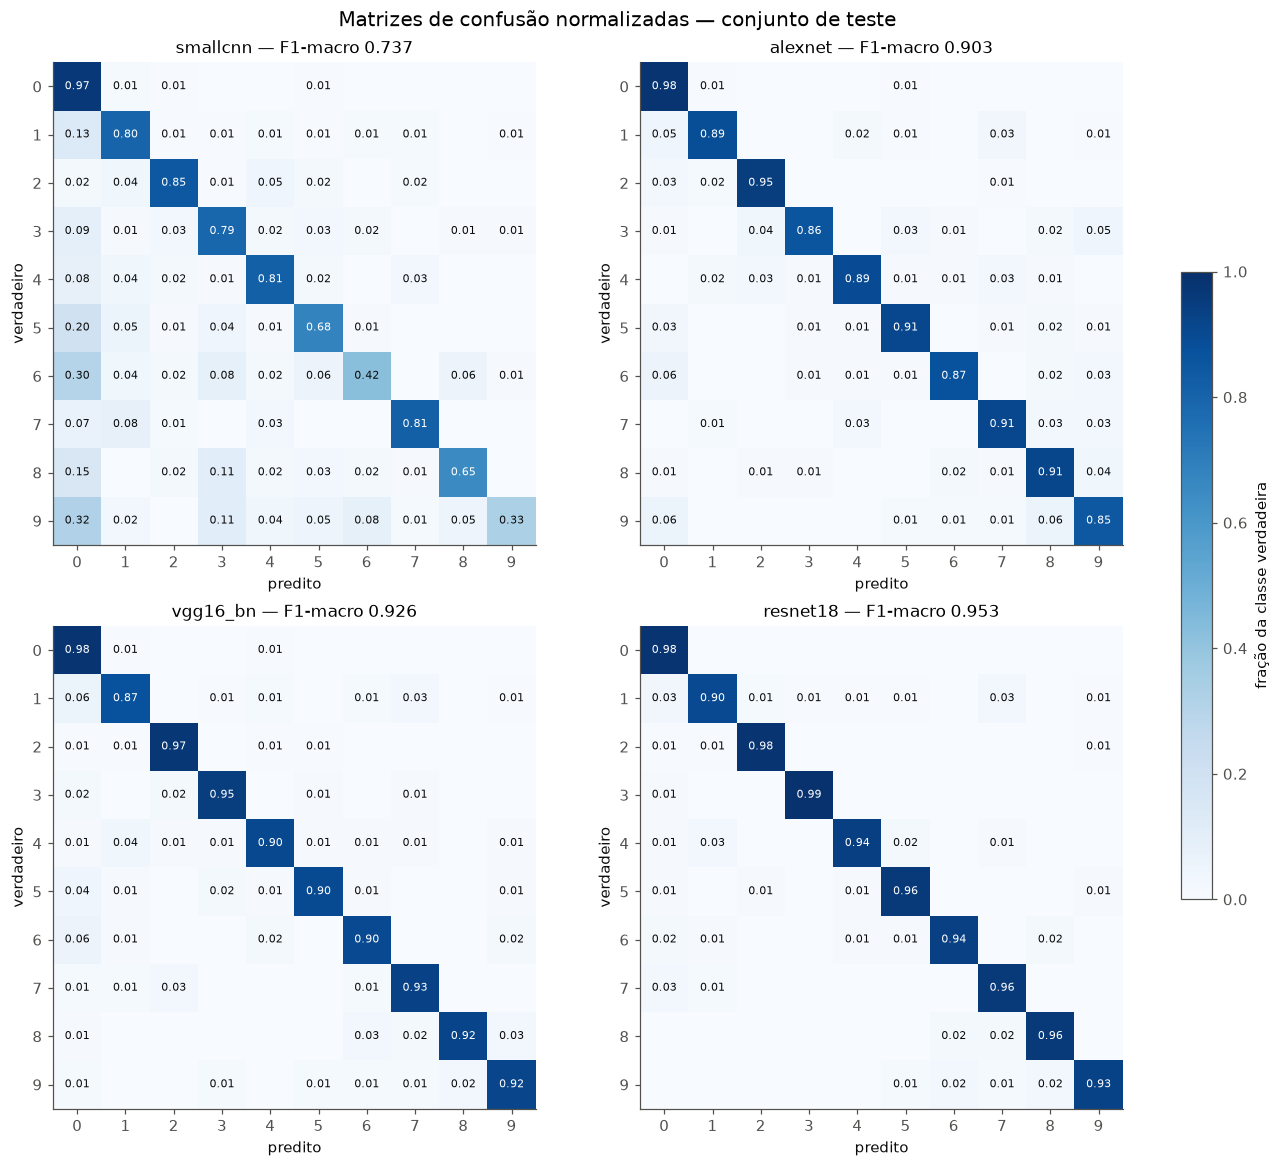

In [25]:
# figures/confusion_matrices.png — normalizadas pela classe verdadeira (linhas somam 1)
fig, axs = plt.subplots(2, 2, figsize=(12, 10.5), layout='constrained')
for ax, name in zip(axs.ravel(), MODELS):
    cm = confusion_matrix(y_true, PREDS[name], labels=range(10), normalize='true')
    im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            if cm[i, j] >= 0.005:
                ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=7,
                        color='white' if cm[i, j] > 0.55 else INK)
    f1 = results.set_index('model').loc[name, 'f1_macro']
    ax.set(title=f'{name} — F1-macro {f1:.3f}', xlabel='predito', ylabel='verdadeiro', xticks=range(10), yticks=range(10))
    ax.grid(False)
fig.colorbar(im, ax=axs, shrink=0.6, label='fração da classe verdadeira')
fig.suptitle('Matrizes de confusão normalizadas — conjunto de teste', fontsize=13)
plt.savefig(FIG / 'confusion_matrices.png'); plt.show()

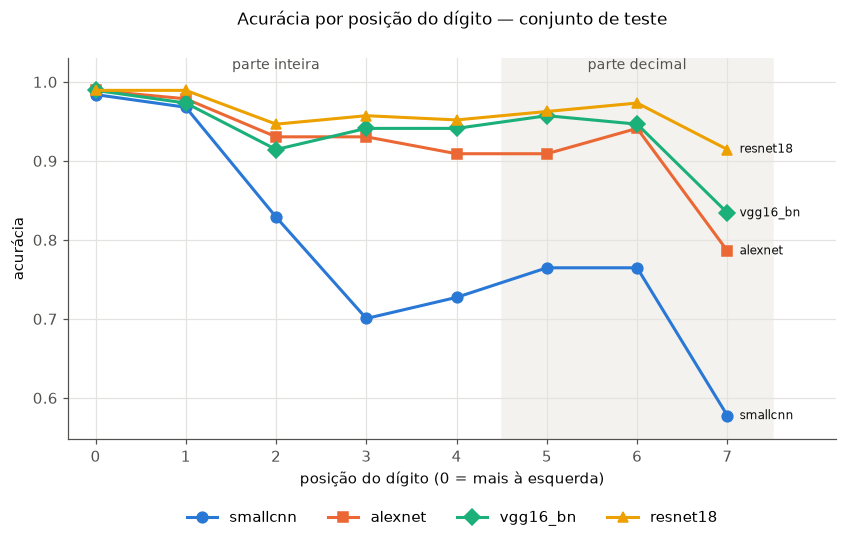

,smallcnn,alexnet,vgg16_bn,resnet18
0,0.9840,0.9893,0.9893,0.9893
1,0.9679,0.9786,0.9733,0.9893
2,0.8289,0.9305,0.9144,0.9465
3,0.7005,0.9305,0.9412,0.9572
4,0.7273,0.9091,0.9412,0.9519
5,0.7647,0.9091,0.9572,0.9626
6,0.7647,0.9412,0.9465,0.9733
7,0.5775,0.7861,0.8342,0.9144


In [26]:
# figures/accuracy_by_position.png
pos = te_meta.position.values
acc_pos = pd.DataFrame({name: pd.Series(PREDS[name] == y_true).groupby(pos).mean() for name in MODELS})
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axvspan(4.5, 7.5, color='#f3f2ef', zorder=0)
ax.text(2, 1.012, 'parte inteira', ha='center', va='bottom', color=INK2, fontsize=9)
ax.text(6, 1.012, 'parte decimal', ha='center', va='bottom', color=INK2, fontsize=9)
for name in MODELS:
    ax.plot(acc_pos.index, acc_pos[name], marker=MARKERS[name], color=COLORS[name], label=name)
    ax.annotate(name, (7, acc_pos[name].iloc[-1]), xytext=(8, 0), textcoords='offset points', va='center', fontsize=8, color=INK)
ax.set(xlabel='posição do dígito (0 = mais à esquerda)', ylabel='acurácia', xticks=range(8), xlim=(-0.3, 8.2))
ax.set_ylim(acc_pos.values.min() - 0.03, 1.03)
ax.set_title('Acurácia por posição do dígito — conjunto de teste', pad=22)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=4)
plt.savefig(FIG / 'accuracy_by_position.png'); plt.show()
acc_pos.round(4)

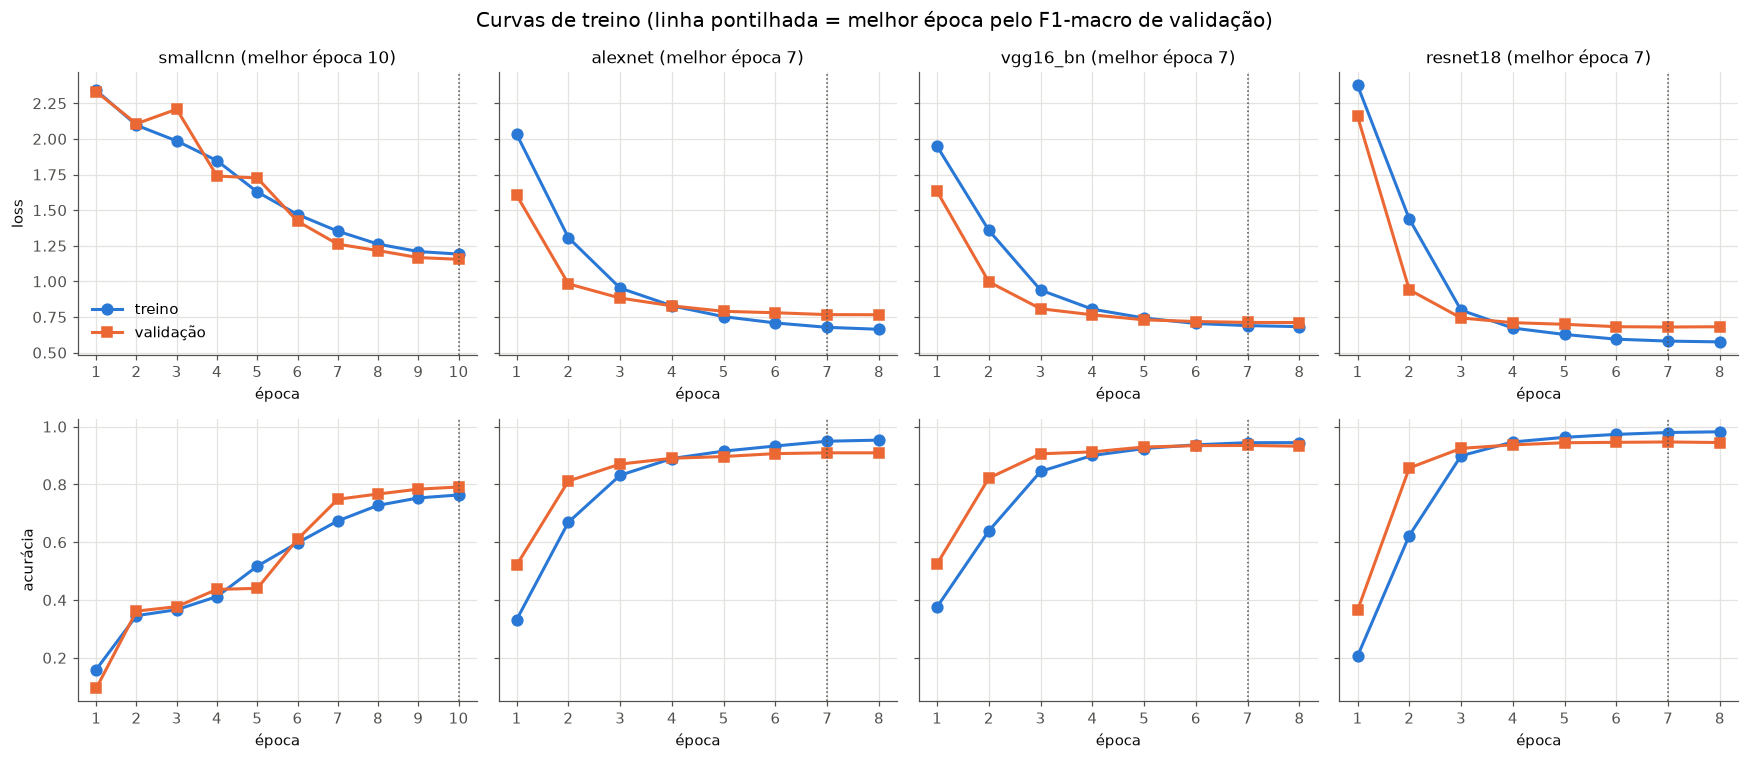

In [27]:
# figures/training_curves.png — loss e acurácia, treino × validação
fig, axs = plt.subplots(2, 4, figsize=(16, 7), sharey='row')
for j, name in enumerate(MODELS):
    h = pd.read_csv(ROOT / f'history_{name}.csv')
    best = h.loc[h.val_f1.idxmax(), 'epoch']
    for i, (tr, va, lab) in enumerate([('train_loss', 'val_loss', 'loss'), ('train_acc', 'val_acc', 'acurácia')]):
        ax = axs[i, j]
        ax.plot(h.epoch, h[tr], marker='o', color='#2a78d6', label='treino')
        ax.plot(h.epoch, h[va], marker='s', color='#eb6834', label='validação')
        ax.axvline(best, color=INK2, linestyle=':', linewidth=1)
        ax.set(xlabel='época', xticks=h.epoch)
        if j == 0:
            ax.set_ylabel(lab)
        if i == 0:
            ax.set_title(f'{name} (melhor época {best})')
axs[0, 0].legend()
fig.suptitle('Curvas de treino (linha pontilhada = melhor época pelo F1-macro de validação)', fontsize=13)
plt.tight_layout(); plt.savefig(FIG / 'training_curves.png'); plt.show()

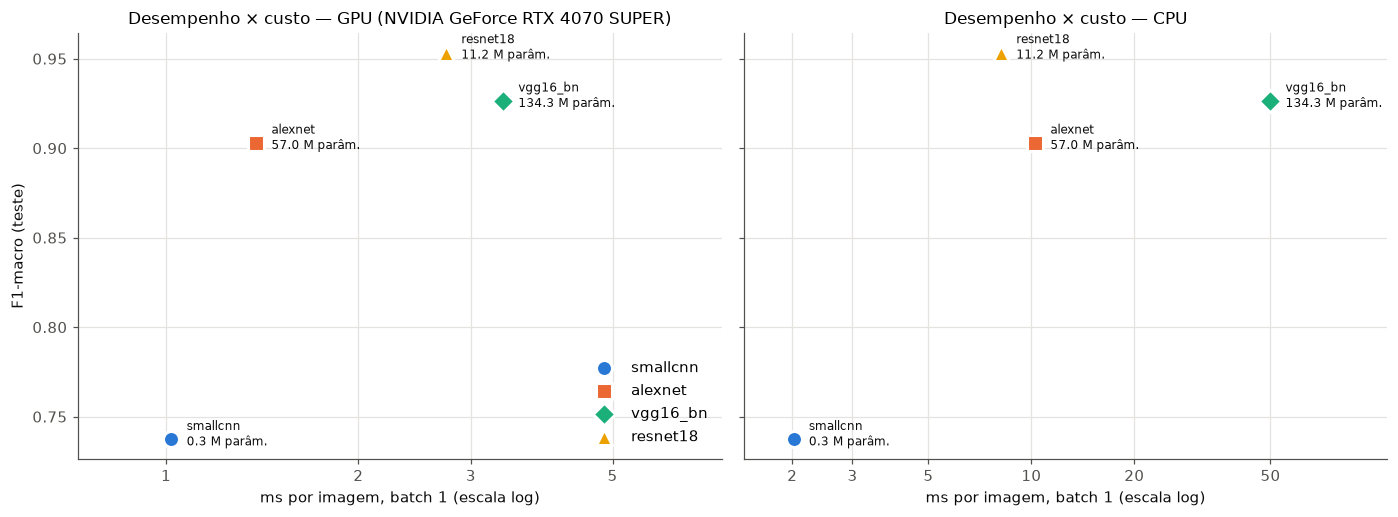

In [28]:
# figures/performance_vs_cost.png — F1-macro × tempo de inferência (GPU e CPU em painéis separados)
lat_cpu = pd.read_csv(REP / 'latency_cpu.csv').set_index('model').ms_per_image_cpu
res = results.set_index('model')
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, (xs, dev) in zip(axs, [(res.ms_per_image, f'GPU ({torch.cuda.get_device_name(0) if CUDA else DEVICE})'),
                               (lat_cpu, 'CPU')]):
    for name in MODELS:
        ax.scatter(xs[name], res.loc[name, 'f1_macro'], s=110, marker=MARKERS[name],
                   color=COLORS[name], edgecolor='white', linewidth=2, zorder=3, label=name)
        ax.annotate(f"{name}\n{res.loc[name, 'params_M']:.1f} M parâm.", (xs[name], res.loc[name, 'f1_macro']),
                    xytext=(10, -4), textcoords='offset points', fontsize=8, color=INK)
    ax.set_xscale('log')
    ticks = [t for t in (0.5, 1, 2, 3, 5, 10, 20, 50, 100) if xs.min() / 1.6 <= t <= xs.max() * 1.6]
    ax.set_xticks(ticks, [f'{t:g}' for t in ticks]); ax.minorticks_off()
    ax.set_xlim(xs.min() / 1.4, xs.max() * 2.2)
    ax.set(xlabel=f'ms por imagem, batch 1 (escala log)', title=f'Desempenho × custo — {dev}')
axs[0].set_ylabel('F1-macro (teste)')
axs[0].legend(loc='lower right')
plt.tight_layout(); plt.savefig(FIG / 'performance_vs_cost.png'); plt.show()

In [29]:
# Galeria: 16 erros mais confiantes de cada modelo (saída removida antes do commit)
for name in MODELS:
    probs, pred = PROBS[name], PREDS[name]
    err = np.where(pred != y_true)[0]
    err = err[np.argsort(-probs[err, pred[err]])][:16]
    fig, axs = plt.subplots(2, 8, figsize=(13, 4.2))
    for ax, i in zip(axs.ravel(), err):
        ax.imshow(Xte[i].permute(1, 2, 0).numpy())
        ax.set_title(f'p={pred[i]} ({probs[i, pred[i]]:.2f})\nv={y_true[i]} pos {te_meta.position[i]}', fontsize=8)
        ax.axis('off')
    for ax in axs.ravel()[len(err):]:
        ax.axis('off')
    fig.suptitle(f'{name}: 16 erros mais confiantes (p = predito, v = verdadeiro)')
    plt.tight_layout(); plt.show()

## Análises de apoio às questões

Números usados nas respostas do README: pares mais confundidos, relação entre `acc_digit` e `acc_reading`,
distribuição de parâmetros por bloco e auditoria dos recortes errados com o melhor modelo.

In [30]:
# Q5.2 — pares de classes mais confundidos (soma das duas direções)
pairs = []
for name in MODELS:
    cm = confusion_matrix(y_true, PREDS[name], labels=range(10))
    for a in range(10):
        for b in range(a + 1, 10):
            pairs.append(dict(model=name, pair=f'{a}↔{b}', count=cm[a, b] + cm[b, a], a_to_b=cm[a, b], b_to_a=cm[b, a]))
pairs = pd.DataFrame(pairs)
top_pairs = pairs.sort_values(['model', 'count'], ascending=[True, False]).groupby('model').head(5)
top_pairs.to_csv(REP / 'top_confused_pairs.csv', index=False)
print(pairs.groupby('pair')['count'].sum().sort_values(ascending=False).head(8).to_string())
top_pairs

pair
0↔1    56
0↔6    48
0↔5    36
0↔9    33
0↔8    25
1↔7    24
1↔4    21
8↔9    20


,model,pair,count,a_to_b,b_to_a
45,alexnet,0↔1,10,3,7
89,alexnet,8↔9,9,4,5
50,alexnet,0↔6,7,1,6
49,alexnet,0↔5,6,3,3
59,alexnet,1↔7,6,5,1
135,resnet18,0↔1,7,2,5
149,resnet18,1↔7,5,4,1
146,resnet18,1↔4,4,1,3
175,resnet18,6↔8,4,2,2
138,resnet18,0↔4,3,2,1


In [31]:
# Q5.3 — acc_reading × acc_digit: erros por imagem e o que se esperaria com erros independentes
rows = []
for name in MODELS:
    wrong = pd.Series(PREDS[name] != y_true).groupby(te_meta.image_id).sum()
    a = (PREDS[name] == y_true).mean()
    rows.append(dict(model=name, acc_digit=a, acc_digit_pow8=a ** 8, acc_reading=(wrong == 0).mean(),
                     imgs_1_erro=(wrong == 1).sum(), imgs_2a3_erros=wrong.between(2, 3).sum(), imgs_4mais_erros=(wrong >= 4).sum()))
reading = pd.DataFrame(rows).round(4)
reading.to_csv(REP / 'reading_analysis.csv', index=False)
reading

,model,acc_digit,acc_digit_pow8,acc_reading,imgs_1_erro,imgs_2a3_erros,imgs_4mais_erros
0,smallcnn,0.7894,0.1509,0.2567,64,45,30
1,alexnet,0.9218,0.5213,0.6310,43,20,6
2,vgg16_bn,0.9372,0.5950,0.7005,37,14,5
3,resnet18,0.9606,0.7248,0.8449,17,7,5


In [32]:
# Q4.2 — onde estão os parâmetros (features convolucionais × classificador)
rows = []
for name in MODELS:
    m, _, _ = build_model(name)
    if name in ('alexnet', 'vgg16_bn'):
        parts = {'features (conv)': m.features, 'classifier (FC)': m.classifier}
    elif name == 'resnet18':
        parts = {'features (conv)': nn.ModuleList([m.conv1, m.bn1, m.layer1, m.layer2, m.layer3, m.layer4]), 'classifier (FC)': m.fc}
    else:
        parts = {'features (conv)': m.features, 'classifier (FC)': m.head}
    tot = count_params(m)
    for part, mod in parts.items():
        rows.append(dict(model=name, part=part, params_M=count_params(mod) / 1e6, share=count_params(mod) / tot))
    if name in ('alexnet', 'vgg16_bn'):
        fc1 = next(l for l in m.classifier if isinstance(l, nn.Linear))
        rows.append(dict(model=name, part=f'  só a 1ª FC ({fc1.in_features}→{fc1.out_features})',
                         params_M=count_params(fc1) / 1e6, share=count_params(fc1) / tot))
params_parts = pd.DataFrame(rows).round(4)
params_parts.to_csv(REP / 'params_by_part.csv', index=False)
params_parts

,model,part,params_M,share
0,smallcnn,features (conv),0.2875,0.9955
1,smallcnn,classifier (FC),0.0013,0.0045
2,alexnet,features (conv),2.4697,0.0433
3,alexnet,classifier (FC),54.5751,0.9567
4,alexnet,só a 1ª FC (9216→4096),37.7528,0.6618
5,vgg16_bn,features (conv),14.7231,0.1096
6,vgg16_bn,classifier (FC),119.5868,0.8904
7,vgg16_bn,só a 1ª FC (25088→4096),102.7645,0.7651
8,resnet18,features (conv),11.1765,0.9995
9,resnet18,classifier (FC),0.0051,0.0005


In [33]:
# Q3.2 — auditoria dos recortes errados com o melhor modelo (maior F1-macro no teste).
# Para cada faixa: quantos dos 8 dígitos o modelo acerta na orientação usada e com a faixa girada 180°.
best_name = results.sort_values('f1_macro', ascending=False).model.iloc[0]
cfg = CFG[best_name]
model, _, _ = build_model(best_name)
model.load_state_dict(torch.load(CKPT / f'{best_name}.pt', map_location='cpu')); model.to(DEVICE)


def strip_to_crops(strip_bgr):
    rgb = strip_bgr[..., ::-1]
    return torch.from_numpy(np.stack([rgb[:, k * CW:(k + 1) * CW] for k in range(NPOS)]).copy()).permute(0, 3, 1, 2)


audit = []
for r in sm.itertuples():
    s = cv2.imread(str(DIGITS / 'strips' / f'{r.image_id}.png'))
    lab = np.array([int(c) for c in r.label])
    p0 = predict(model, strip_to_crops(s), cfg['size']).argmax(1)
    p1 = predict(model, strip_to_crops(cv2.rotate(s, cv2.ROTATE_180)), cfg['size']).argmax(1)
    audit.append(dict(image_id=r.image_id, split=r.split, hits=(p0 == lab).sum(), hits_flipped=(p1 == lab).sum()))
audit = sm.merge(pd.DataFrame(audit), on=['image_id', 'split'])


def category(r):
    if r.integer_only:
        return 'polígono só com inteiros'
    if r.hits_flipped >= r.hits + 3:
        return 'orientação errada (180°)'
    if r.hits <= 4:
        return 'outro desalinhamento/ilegível'
    return 'ok'


audit['category'] = audit.apply(category, axis=1)
audit.to_csv(REP / 'crop_audit.csv', index=False)
print('modelo usado na auditoria:', best_name)
print(pd.crosstab(audit.category, audit.split, margins=True))

modelo usado na auditoria: resnet18
split                          test  train  val   All
category                                             
ok                              181    841  174  1196
orientação errada (180°)          1      8    3    12
outro desalinhamento/ilegível     1      0    1     2
polígono só com inteiros          4     21    8    33
All                             187    870  186  1243


In [34]:
# Impacto no teste: métricas recalculadas excluindo imagens com recorte errado (só análise; results.csv não muda).
# "sem_so_inteiros": exclui só os polígonos "só inteiros" (auditoria visual, independe do modelo).
# "clean": exclui também as categorias detectadas pela auditoria com a resnet18 — critério que usa os erros do próprio
#          modelo no teste, portanto otimista para a resnet18.
int_ids = set(audit[audit.integer_only].image_id)
bad_ids = set(audit[audit.category != 'ok'].image_id)


def metrics_excluding(p, ids):
    keep = ~te_meta.image_id.isin(ids).values
    acc = (p[keep] == y_true[keep]).mean()
    reading = pd.Series(p[keep] == y_true[keep]).groupby(te_meta.image_id[keep].values).all().mean()
    return acc, reading


rows = []
for name in MODELS:
    p = PREDS[name]
    a1, r1 = metrics_excluding(p, int_ids)
    a2, r2 = metrics_excluding(p, bad_ids)
    rows.append(dict(model=name, acc_digit_all=(p == y_true).mean(), acc_digit_sem_so_inteiros=a1, acc_digit_clean=a2,
                     acc_reading_all=pd.Series(p == y_true).groupby(te_meta.image_id).all().mean(),
                     acc_reading_sem_so_inteiros=r1, acc_reading_clean=r2))
clean = pd.DataFrame(rows).round(4)
clean.to_csv(REP / 'metrics_without_bad_crops.csv', index=False)
print('imagens de teste excluídas — só inteiros:', len(int_ids & set(te_meta.image_id)),
      '| todas as categorias:', len(bad_ids & set(te_meta.image_id)))
clean

imagens de teste excluídas — só inteiros: 4 | todas as categorias: 6


,model,acc_digit_all,acc_digit_sem_so_inteiros,acc_digit_clean,acc_reading_all,acc_reading_sem_so_inteiros,acc_reading_clean
0,smallcnn,0.7894,0.7985,0.8046,0.2567,0.2623,0.2652
1,alexnet,0.9218,0.9317,0.9372,0.6310,0.6448,0.6519
2,vgg16_bn,0.9372,0.9467,0.9551,0.7005,0.7158,0.7238
3,resnet18,0.9606,0.9706,0.9786,0.8449,0.8634,0.8729


In [35]:
show_strips(audit[audit.category == 'orientação errada (180°)'], 'Auditoria: orientação provavelmente errada', n=12)
show_strips(audit[audit.category == 'outro desalinhamento/ilegível'].sort_values('hits'), 'Auditoria: outros recortes ruins', n=12)